# Document clustering | K-Means

Group articles based on normalized TF-IDF features, optionally reduced with truncated SVD. Interpret groups through internal clustering metrics, prominent phrases, and the website's original section/topic metadata.

**Scope:** These are unsupervised clusters; article sections are **not** training labels. The supplied notebook has no saved fitted-model outputs, and its original unsupervised grid-search scorer needs attention before a complete run.


## Prepare clustering dependencies

Load text processing, vectorization, dimensionality reduction, clustering, and charting libraries. Keep the original model seeds and numerical settings.


In [1]:
# Import the packages used for text features, clustering and internal validation.

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
from collections import Counter
from sklearn.cluster import HDBSCAN

from sklearn.cluster import KMeans
from sklearn.metrics import make_scorer, silhouette_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.model_selection import GridSearchCV
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer

import nltk
from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet
from nltk.corpus import stopwords
from nltk import pos_tag
from spacy.lang.en.stop_words import STOP_WORDS as SPACY_STOP_WORDS

from mpl_toolkits.mplot3d import Axes3D 

import gensim
from gensim.models import Word2Vec

import warnings
warnings.filterwarnings('ignore')

nltk.data.path.append("./data")
nltk.download('punkt', download_dir="./data")
nltk.download("punkt_tab", download_dir="./data")
nltk.download("averaged_perceptron_tagger", download_dir="./data")
nltk.download("averaged_perceptron_tagger_eng", download_dir="./data")
nltk.download('stopwords', download_dir="./data")
nltk.download('wordnet', download_dir="./data")



[nltk_data] Downloading package punkt to ./data...
[nltk_data] Refusing to install into
[nltk_data]     '/home/mouelhis/Private/github/new_dsac/twm/data': it
[nltk_data]     is writable by, or owned by, another account, so a
[nltk_data]     file swapped in during the install would be installed
[nltk_data]     as trusted data. Make it private to its owner (chmod
[nltk_data]     go-w).
[nltk_data] Downloading package punkt_tab to ./data...
[nltk_data] Refusing to install into
[nltk_data]     '/home/mouelhis/Private/github/new_dsac/twm/data': it
[nltk_data]     is writable by, or owned by, another account, so a
[nltk_data]     file swapped in during the install would be installed
[nltk_data]     as trusted data. Make it private to its owner (chmod
[nltk_data]     go-w).
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     ./data...
[nltk_data] Refusing to install into
[nltk_data]     '/home/mouelhis/Private/github/new_dsac/twm/data': it
[nltk_data]     is writable

False

## Assemble the textual feature source

Read the article CSV, drop unavailable bodies, and concatenate each headline with its article text before feature extraction.


In [2]:
# Read the article snapshot and combine title and body into a single text field.

df = pd.read_csv("./data/youth_information_articles.csv", encoding='utf-8-sig')


df['article_title'] = df['article_title'].fillna('').astype(str)



df = df[df['article_body'] != 'N/A']
df = df.dropna(subset=['article_body'])



df['article_body'] = df['article_title'] + " " + df['article_body']

print(f"Successfully loaded {len(df)} articles.")

Successfully loaded 2973 articles.


**How to interpret this step.** Source labels are retained only for post-clustering interpretation; they are not used as supervised training targets.


## Clean article text with POS-aware lemmatization

Use the existing corpus-specific word exclusions, punctuation rules, and WordNet tag mapping to create the normalized text field.


In [3]:
# Normalize text using the existing WordNet POS mapping and stopword rules.







def wordnet_tag_from_treebank(treebank_tag):
    """
    Convert Penn Treebank tags into the part-of-speech codes used by WordNet.
    """
    if treebank_tag.startswith('J'):
        return wordnet.ADJ
    elif treebank_tag.startswith('V'):
        return wordnet.VERB
    elif treebank_tag.startswith('N'):
        return wordnet.NOUN
    elif treebank_tag.startswith('R'):
        return wordnet.ADV
    else:
        
        return wordnet.NOUN


lemmatizer = WordNetLemmatizer()






stop_words = set(SPACY_STOP_WORDS)



domain_stopwords = [
    
    'spunout', 'spun', 'out', 'ie', 'ireland', 'irish', 'www', 'http', 'https', 'com', 
    'copyright', 'privacy', 'policy', 'terms', 'conditions', 'login', 'sign', 'register',
    
    
    'page', 'section', 'footer', 'header', 'sidebar', 'widget', 'nav', 'advertisement', 'ad',
    'promo', 'cookie', 'script', 'javascript', 'css', 'html', 'body', 'main', 'published', 'updated',
    'author', 'post', 'article', 'url', 'permalink',
    
    
    
    'day', 'new', 'good', 'bad',
    'check', 'try', 'keep',
    'like', 'just', 'get', 'also', 'would', 'could', 'one', 'make', 'use', 'way', 'well', 
    'time', 'know', 'need', 'really', 'thing', 'think', 'much', 'even', 'still', 'another', 
    'every', 'go', 'want', 'take', 'find', 'look', 'come', 'year', 'old', 'may', 'might',
    
    
    'click', 'read', 'link', 'menu', 'comment', 'reply',
    
    
    'u', 'ur', 'im', 'dont', 'cant', 'wont', 'oh', 'ok', 'please', 'thanks', 'thank', 'yes', 'no'
]


stop_words.update(domain_stopwords)


def normalize_article_text(text):
    """
    Refined text cleaning function.
    Includes explicit removal of separator artifacts (e.g., ___, ///), 
    Normalize text by removing markup and irrelevant tokens, then lemmatize with POS information.
    """
    
    text = str(text).lower()
    
    
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'<.*?>', ' ', text)
    
    
    
    text = re.sub(r'[\_\-\.]{1,}', ' ', text)
    
    text = re.sub(r'[/\\]', ' ', text)

    
    text = re.sub(r"\'", "", text)
    
    
    
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    
    
    text = re.sub(r'\s+[a-z]\s+', ' ', text)
    
    
    words = text.split()
    
    
    
    
    tagged_words = pos_tag(words)
    
    
    lemmatized_words = []
    for word, tag in tagged_words:
        
        wn_tag = wordnet_tag_from_treebank(tag)
        
        
        
        lemma = lemmatizer.lemmatize(word, pos=wn_tag)
        lemmatized_words.append(lemma)
    
    
    
    filtered_words = [word for word in lemmatized_words if word not in stop_words and len(word) > 2]
    
    return " ".join(filtered_words)

**How to interpret this step.** Any topic interpretation should be based on tokens that survive this exact preprocessing.


## Create the cleaned feature and metadata series

Prepare the text sequence for vectorization and keep source section/topic labels available for subsequent cluster breakdowns.


In [4]:
# Build clean text and retain website metadata for later descriptive comparisons.




print("Applying Text Cleaning (POS + Lemmatization)...")
df['normalized_text'] = df['article_body'].apply(normalize_article_text)




X_raw = df['article_body']
X = df['normalized_text']

y = df['source_section']
t = df['source_topic']

Applying Text Cleaning (POS + Lemmatization)...


## Construct TF-IDF representations

Use the original unigram-to-trigram TF-IDF settings, term-frequency scaling, and document-frequency cutoffs.


In [5]:
# Fit a TF-IDF model using the existing term-frequency and n-gram configuration.


print("Vectorizing with TF-IDF...")




tfidf_vectorizer = TfidfVectorizer(
    
    max_features=20000,           
    
    
    
    ngram_range=(1, 3),
    
    
    
    min_df=3,                     
    
    
    max_df=0.7,                    
    
    
    sublinear_tf=True,            
    
    
    norm='l2'                     
)


X_tfidf_matrix = tfidf_vectorizer.fit_transform(X)

print(f"TF-IDF Shape: {X_tfidf_matrix.shape}")

Vectorizing with TF-IDF...
TF-IDF Shape: (2973, 20000)


**How to interpret this step.** TF-IDF downweights globally common expressions while retaining terms that help distinguish articles.


## Reduce dimensionality with truncated SVD

Select a component count using the original cumulative-variance threshold and project the TF-IDF matrix into that latent space.


In [6]:
# Select an SVD dimension from cumulative explained variance and reduce the term matrix.



def choose_svd_component_count(X, variance_threshold=0.90, max_components=5000):
    n_samples, n_features = X.shape
    
    
    
    search_limit = min(n_samples, max_components, n_features)
    
    print(f"Analyzing variance for up to {search_limit} components...")
    
    
    svd_analyzer = TruncatedSVD(n_components=search_limit, random_state=42)
    svd_analyzer.fit(X)
    
    
    
    explained_variance_ratio = svd_analyzer.explained_variance_ratio_
    cumulative_variance = np.cumsum(explained_variance_ratio)
    
    
    
    k_indices = np.where(cumulative_variance >= variance_threshold)[0]
    
    if len(k_indices) > 0:
        optimal_k = k_indices[0] + 1
        variance_acquired = cumulative_variance[optimal_k - 1]
    else:
        
        optimal_k = search_limit
        variance_acquired = cumulative_variance[-1]
        print(f"Warning: Threshold {variance_threshold*100}% not reached within {search_limit} components.")


    print(f"Target Variance:   {variance_threshold*100}%")
    print(f"Optimal K found:   {optimal_k}")
    print(f"Actual Variance:   {variance_acquired:.4f} ({variance_acquired*100:.2f}%)")

    return optimal_k





best_k = choose_svd_component_count(X_tfidf_matrix, variance_threshold=0.90)


print(f"\nApplying TruncatedSVD with K={best_k}...")
svd_final = TruncatedSVD(n_components=best_k, random_state=42)

X_tfidf_reduced_matrix = svd_final.fit_transform(X_tfidf_matrix)

print(f"Final Reduced Matrix Shape: {X_tfidf_reduced_matrix.shape}")

Analyzing variance for up to 2973 components...
Target Variance:   90.0%
Optimal K found:   1988
Actual Variance:   0.9001 (90.01%)

Applying TruncatedSVD with K=1988...
Final Reduced Matrix Shape: (2973, 1988)


**How to interpret this step.** Retained variance measures representation coverage, not clustering performance. The chosen dimension can be large.


## Normalize latent document vectors

Scale each reduced vector to unit length prior to distance-based clustering.


In [7]:
# Normalize the reduced vectors to keep their relative direction meaningful.

from sklearn.preprocessing import Normalizer




normalizer = Normalizer()
X_tfidf_matrix_normalized = normalizer.fit_transform(X_tfidf_reduced_matrix)

print("\nData normalized for Spherical K-Means...")


Data normalized for Spherical K-Means...


**How to interpret this step.** With unit-length vectors, Euclidean separation has a direct relationship to cosine similarity.


## Compare K-Means cluster counts

Fit the original set of candidate K-Means models and chart the silhouette and Davies–Bouldin criteria.


Evaluating clusters from K=2 to K=10...

K=2: Davies-Bouldin=6.3840 | Silhouette=0.0095
K=3: Davies-Bouldin=6.3593 | Silhouette=0.0134
K=4: Davies-Bouldin=5.6369 | Silhouette=0.0167
K=5: Davies-Bouldin=7.5596 | Silhouette=0.0182
K=6: Davies-Bouldin=6.8347 | Silhouette=0.0177
K=7: Davies-Bouldin=7.0372 | Silhouette=0.0185
K=8: Davies-Bouldin=6.3247 | Silhouette=0.0179
K=9: Davies-Bouldin=6.1164 | Silhouette=0.0195

Plot successfully saved to: ./images/kmeans_clusters_dbouldin_silhouette.png


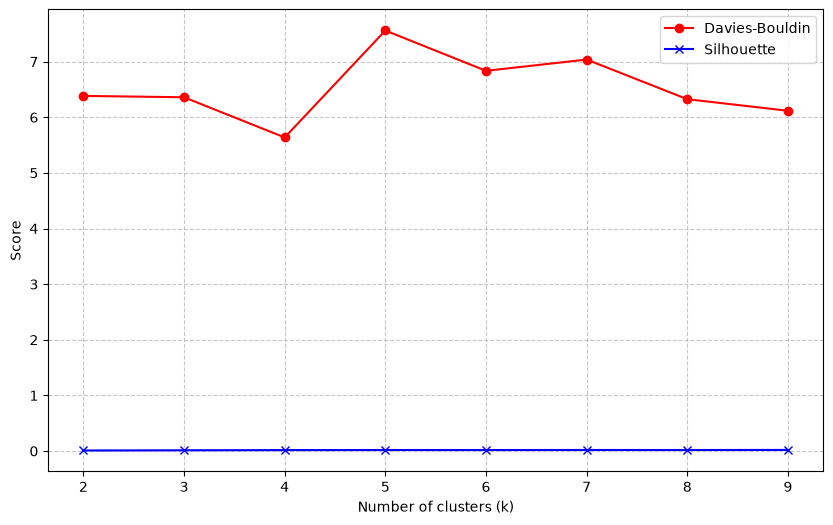

In [8]:
# Compare K-Means cluster counts with internal separation metrics.

import os
from sklearn.metrics import davies_bouldin_score, silhouette_score


db_scores = []
sil_scores = []


X_data = X_tfidf_matrix_normalized.copy()

print("Evaluating clusters from K=2 to K=10...\n")


for k in range(2, 10):
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=43, 
        n_init=10,        
        max_iter=100,     
        init='k-means++'
    )

    
    labels = kmeans.fit_predict(X_data)
    
    
    db_index = davies_bouldin_score(X_data, labels)
    db_scores.append(db_index)
    
    
    sil_score = silhouette_score(X_data, labels)
    sil_scores.append(sil_score)
    
    print(f"K={k}: Davies-Bouldin={db_index:.4f} | Silhouette={sil_score:.4f}")


fig, ax = plt.subplots(figsize=(10, 6))


ax.plot(range(2, 10), db_scores, marker='o', label='Davies-Bouldin', color='red')


ax.plot(range(2, 10), sil_scores, marker='x', label='Silhouette', color='blue')


ax.set_xlabel('Number of clusters (k)')
ax.set_ylabel('Score')



ax.legend()


ax.grid(True, linestyle='--', alpha=0.7)



folder_name = "./images/"
file_name = "kmeans_clusters_dbouldin_silhouette.png"


if not os.path.exists(folder_name):
    os.makedirs(folder_name)


full_path = os.path.join(folder_name, file_name)

plt.savefig(full_path, dpi=300, bbox_inches='tight')

print(f"\nPlot successfully saved to: {full_path}")

plt.show()

**How to interpret this step.** Higher silhouette and lower Davies–Bouldin generally indicate greater internal separation. Neither metric supplies ground-truth labels.


## Search the configured initialization count

Retain the original K-Means estimator and attempted grid search over its initialization counts.


In [9]:
# Evaluate the original K-Means initialization grid; note the scorer limitation in the documentation.

from sklearn.cluster import KMeans
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, silhouette_score
import numpy as np



kmeans = KMeans(
    n_clusters=4,
    random_state=43, 
    init='k-means++',  
    max_iter=100,      
)

param_grid = {
    'n_init': [10, 30, 50],          
}




k_grid_search = GridSearchCV(
    kmeans, 
    param_grid=param_grid, 
    scoring=make_scorer(silhouette_score),    
    cv=3,  
    n_jobs=-1, 
    verbose=1
)

print("Running Optimized Grid Search...")
print("This may take some time as we are testing multiple parameters...\n")



k_grid_search.fit(X_tfidf_matrix_normalized)

print("\nBest Parameters Found:")
print(k_grid_search.best_params_)

Running Optimized Grid Search...
This may take some time as we are testing multiple parameters...

Fitting 3 folds for each of 3 candidates, totalling 9 fits

Best Parameters Found:
{'n_init': 10}


**How to interpret this step.** Compatibility note: the original `make_scorer(silhouette_score)` is not a valid unsupervised GridSearchCV scorer without a custom callable. The original statement is preserved and may fail.


## Compare cluster assignments with source sections

Cross-tabulate predicted clusters against the existing website section labels.


In [10]:
# Compare cluster IDs with source sections as a descriptive cross-tabulation.


best_kmeans = k_grid_search.best_estimator_


k_results_df = pd.DataFrame(X_tfidf_matrix_normalized)


k_results_df['cluster_label'] = best_kmeans.labels_


k_results_df['true_label'] = y


print("\nCluster Composition:")
print(k_results_df.groupby('cluster_label')['true_label'].value_counts().to_string())


Cluster Composition:
cluster_label  true_label       
0              Voices               998
               News                 449
               Health               181
               Life                  78
               Sex_Relationships     46
               Mental_Health         45
               Education              6
               Employment             4
               Lgbti                  1
1              Life                 157
               Employment           102
               News                  50
               Education             42
               Voices                37
               Lgbti                 12
               Health                 8
               Mental_Health          7
               Sex_Relationships      4
2              Voices               251
               Mental_Health        161
               Life                  70
               Health                54
               Sex_Relationships     54
               News      

**How to interpret this step.** A cluster need not align with one section: the grouping is based on text similarity, not section classification.


## Inspect the section/topic composition

Extend the cluster comparison with source topics to identify fine-grained content mixtures.


In [11]:
# Expand the cluster summary to include original topic labels.


best_kmeans = k_grid_search.best_estimator_


k_results_df = pd.DataFrame(X_tfidf_matrix_normalized)


k_results_df['cluster_label'] = best_kmeans.labels_


k_results_df['true_label'] = y

k_results_df['topics'] = t


composition = k_results_df.groupby(['cluster_label', 'true_label', 'topics']).size()

print("\nDetailed Cluster Composition (Cluster > Category > Topic):")
print(composition.to_string())


Detailed Cluster Composition (Cluster > Category > Topic):
cluster_label  true_label         topics                        
0              Education          Leaving_Cert_Cao                    4
                                  School                              1
                                  Study_Exams                         1
               Employment         Apply_Job                           1
                                  Job_Skills                          1
                                  Schemes                             1
                                  Wellbeing                           1
               Health             Alcohol                            24
                                  Drugs                              14
                                  Exercise                           27
                                  Gambling                            4
                                  General                            26
           

**How to interpret this step.** A dominant topic within a cluster can guide naming, but the topic labels are source metadata rather than proof of cluster correctness.


## Project clusters into three dimensions

Use the same three-component SVD projection for visualization, drawn with Matplotlib instead of WebGL-dependent Plotly.


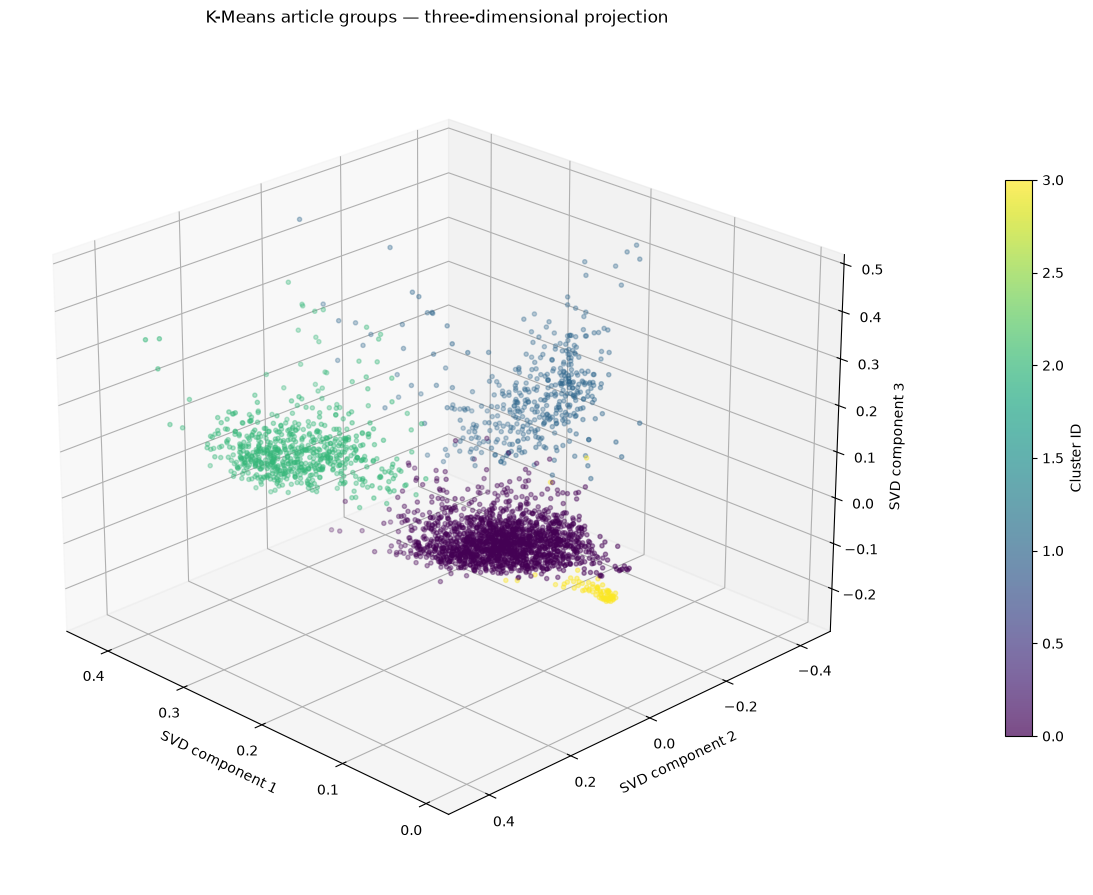

In [12]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD

# Preserve the original three-component projection and random seed.
svd = TruncatedSVD(n_components=3, random_state=43)
X_svd = svd.fit_transform(X_tfidf_matrix_normalized)

# Render the unchanged cluster assignments using Matplotlib rather than WebGL.
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')
points = ax.scatter(
    X_svd[:, 0], X_svd[:, 1], X_svd[:, 2],
    c=best_kmeans.labels_, cmap='viridis', s=9, alpha=0.7
)
ax.set_xlabel('SVD component 1')
ax.set_ylabel('SVD component 2')
ax.set_zlabel('SVD component 3')
ax.set_title('K-Means article groups — three-dimensional projection')
fig.colorbar(points, ax=ax, shrink=0.65, pad=0.12, label='Cluster ID')
ax.view_init(elev=24, azim=135)

# Save a static figure that displays inside VS Code without WebGL.
os.makedirs('./images', exist_ok=True)
fig.savefig('./images/kmeans_clusters_3d.png', dpi=180, bbox_inches='tight')
plt.tight_layout()
plt.show()


**How to interpret this step.** The three-dimensional picture is a simplified view; distances in the plotted projection do not preserve every separation in the full vector space.


## Identify informative words by cluster

Aggregate original TF-IDF scores for documents assigned to each cluster and show the twenty largest terms.



Plot successfully saved to: ./images/kmeans_top_20_words_per_cluster.png


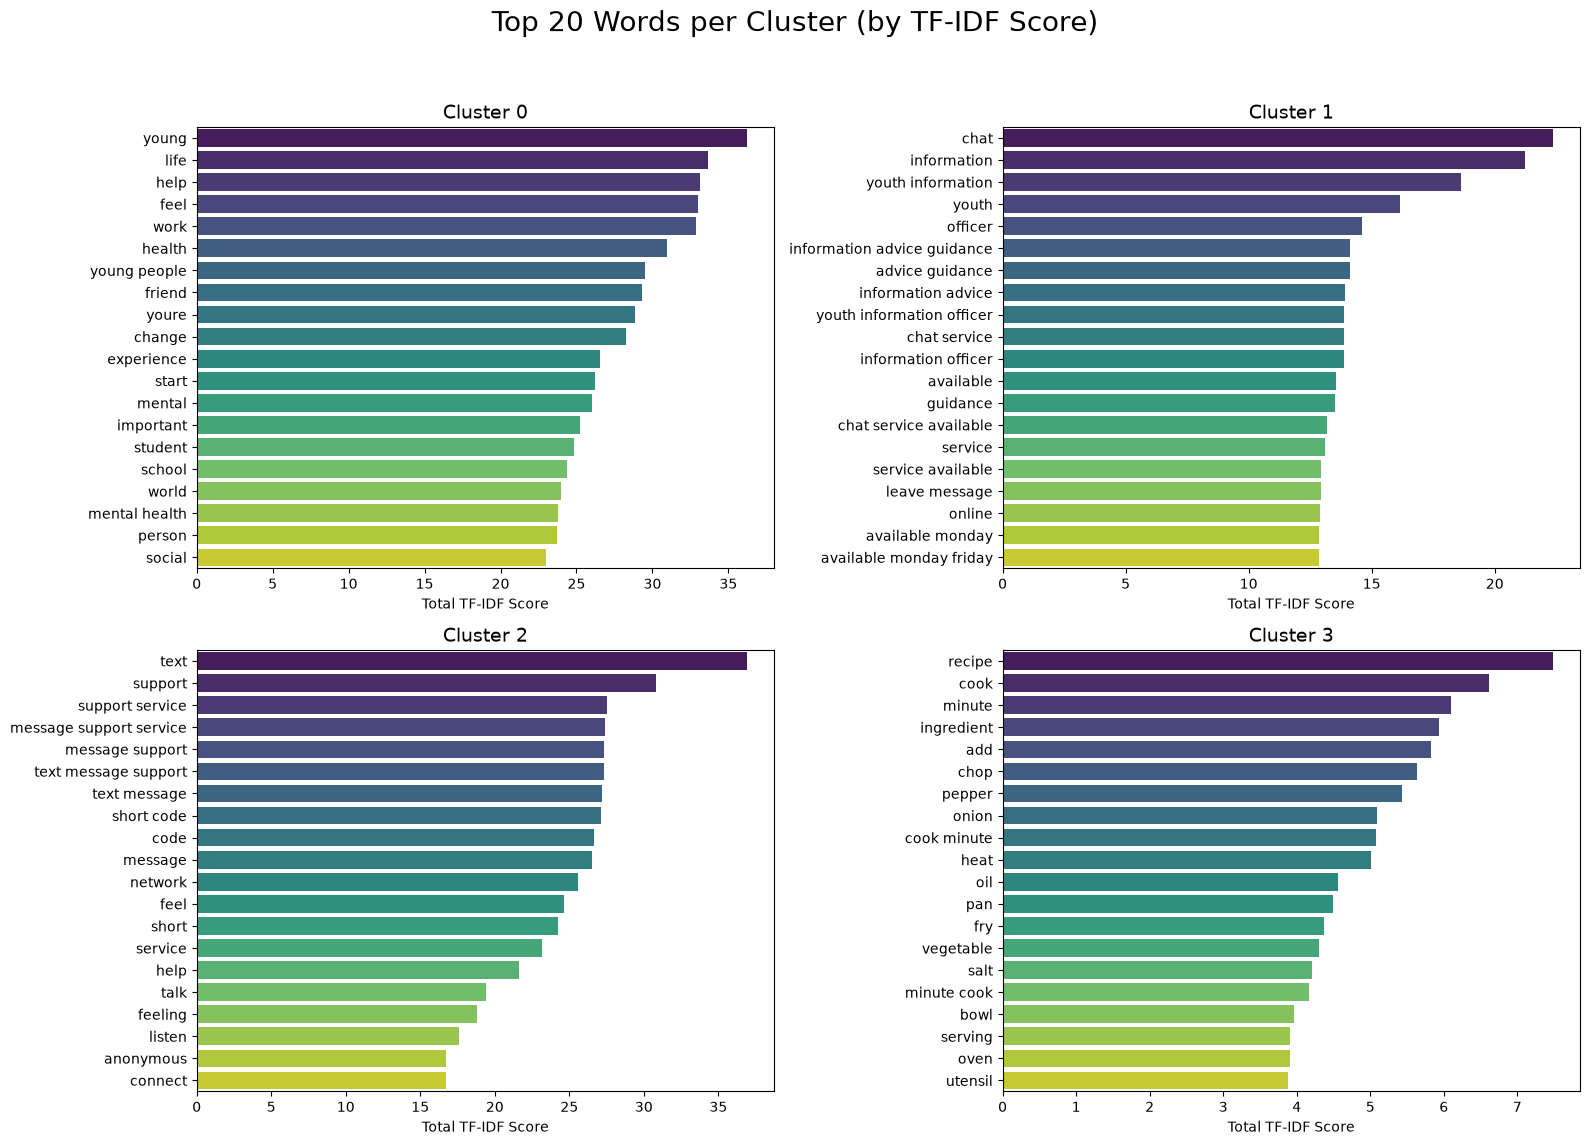

In [13]:
# Aggregate original TF-IDF scores to identify each cluster's highest-weight terms.


feature_names = tfidf_vectorizer.get_feature_names_out()


n_clusters = best_kmeans.n_clusters


fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Top 20 Words per Cluster (by TF-IDF Score)', fontsize=20)


axes = axes.flatten()

for i in range(n_clusters):
    
    cluster_indices = np.where(best_kmeans.labels_ == i)[0]
    
    
    
    cluster_tfidf = X_tfidf_matrix[cluster_indices]
    
    
    
    word_scores = np.array(cluster_tfidf.sum(axis=0)).flatten()
    
    
    
    top_indices = word_scores.argsort()[-20:][::-1]
    
    
    top_words = feature_names[top_indices]
    top_scores = word_scores[top_indices]
    
    
    df_plot = pd.DataFrame({
        'Word': top_words,
        'Score': top_scores
    })
    
    
    sns.barplot(
        ax=axes[i], 
        data=df_plot, 
        x='Score', 
        y='Word', 
        palette='viridis'
    )
    
    axes[i].set_title(f'Cluster {i}', fontsize=14)
    axes[i].set_xlabel('Total TF-IDF Score')
    axes[i].set_ylabel('') 

plt.tight_layout(rect=[0, 0.03, 1, 0.95]) 


folder_name = "./images/"
file_name = "kmeans_top_20_words_per_cluster.png"


if not os.path.exists(folder_name):
    os.makedirs(folder_name)


full_path = os.path.join(folder_name, file_name)

plt.savefig(full_path, dpi=300, bbox_inches='tight')

print(f"\nPlot successfully saved to: {full_path}")

plt.show()

**How to interpret this step.** These are total TF-IDF weights, not causal explanations of how a particular article was assigned.


## Display compact cluster vocabularies

Print the most prominent terms per cluster to support human-readable cluster descriptions.


In [14]:
# Print compact term lists that can guide qualitative group descriptions.

print("Top Words per Cluster (by TF-IDF Score):")
print("-" * 40)

for i in range(n_clusters):
    
    cluster_indices = np.where(best_kmeans.labels_ == i)[0]
    cluster_tfidf = X_tfidf_matrix[cluster_indices]
    word_scores = np.array(cluster_tfidf.sum(axis=0)).flatten()
    top_indices = word_scores.argsort()[-20:][::-1]
    
    top_words = feature_names[top_indices]
    top_scores = word_scores[top_indices]
    
    
    print(f"\nCluster {i}:")
    
    print(", ".join(top_words))
    
    
    
    

Top Words per Cluster (by TF-IDF Score):
----------------------------------------

Cluster 0:
young, life, help, feel, work, health, young people, friend, youre, change, experience, start, mental, important, student, school, world, mental health, person, social

Cluster 1:
chat, information, youth information, youth, officer, information advice guidance, advice guidance, information advice, youth information officer, chat service, information officer, available, guidance, chat service available, service, service available, leave message, online, available monday, available monday friday

Cluster 2:
text, support, support service, message support service, message support, text message support, text message, short code, code, message, network, feel, short, service, help, talk, feeling, listen, anonymous, connect

Cluster 3:
recipe, cook, minute, ingredient, add, chop, pepper, onion, cook minute, heat, oil, pan, fry, vegetable, salt, minute cook, bowl, serving, oven, utensil


## Measure similarity between cluster centers

Compute cosine similarity between average normalized document vectors in each cluster and visualize the matrix.



Plot successfully saved to: ./images/kmeans_inter_cluster_similarity.png


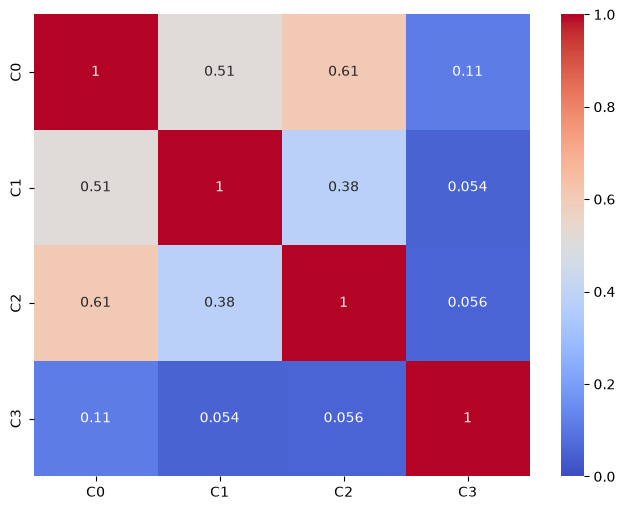

In [15]:
# Measure cosine similarity between mean document vectors from each cluster.

from sklearn.metrics.pairwise import cosine_similarity
import seaborn as sns


centroids = []
for i in range(n_clusters):
    mask = (best_kmeans.labels_ == i)
    centroids.append(X_tfidf_matrix_normalized[mask].mean(axis=0))

centroids = np.array(centroids)


centroid_similarity = cosine_similarity(centroids)


plt.figure(figsize=(8, 6))
sns.heatmap(
    centroid_similarity, 
    annot=True, 
    cmap='coolwarm', 
    xticklabels=[f'C{i}' for i in range(n_clusters)],
    yticklabels=[f'C{i}' for i in range(n_clusters)],
    vmin=0, vmax=1
)



folder_name = "./images/"
file_name = "kmeans_inter_cluster_similarity.png"


if not os.path.exists(folder_name):
    os.makedirs(folder_name)


full_path = os.path.join(folder_name, file_name)

plt.savefig(full_path, dpi=300, bbox_inches='tight')

print(f"\nPlot successfully saved to: {full_path}")

plt.show()

**How to interpret this step.** Large off-diagonal similarity indicates overlap between clusters in representation space; it is not a misclassification rate.


## Review the numeric cluster-similarity table

Display the same pairwise center similarities as a rounded table.


In [16]:
# Present the cluster-similarity matrix in a readable table.


cluster_labels = [f'Cluster {i}' for i in range(n_clusters)]



df_similarity = pd.DataFrame(
    centroid_similarity, 
    index=cluster_labels, 
    columns=cluster_labels
)


df_similarity = df_similarity.round(3)


print("\nInter-Cluster Similarity Matrix:")
print(df_similarity)


Inter-Cluster Similarity Matrix:
           Cluster 0  Cluster 1  Cluster 2  Cluster 3
Cluster 0      1.000      0.513      0.606      0.111
Cluster 1      0.513      1.000      0.379      0.054
Cluster 2      0.606      0.379      1.000      0.056
Cluster 3      0.111      0.054      0.056      1.000


**How to interpret this step.** The diagonal should be 1 for nonzero centroids; interpret off-diagonal entries as relative similarity.


## Inspect articles furthest from their centers

Find the least similar article in each cluster, subject to the original similarity threshold.


In [17]:
# Inspect documents with the weakest resemblance to their assigned centroid.

print("Identifying potential Outliers (weakest links)...\n")

for i in range(n_clusters):
    cluster_mask = (best_kmeans.labels_ == i)
    cluster_docs = X_tfidf_matrix_normalized[cluster_mask]
    
    
    
    centroid = cluster_docs.mean(axis=0).reshape(1, -1)
    
    
    similarities = cosine_similarity(cluster_docs, centroid).flatten()
    
    
    worst_doc_local_index = similarities.argsort()[0]
    
    original_df_indices = np.where(best_kmeans.labels_ == i)[0]
    worst_original_index = original_df_indices[worst_doc_local_index]
    
    score = similarities[worst_doc_local_index]
    
    
    if score < 0.1: 
        title = df['article_title'].iloc[worst_original_index]
        print(f"CLUSTER {i} Outlier (Score: {score:.4f}):")
        print(f"  > {title}\n")

Identifying potential Outliers (weakest links)...

CLUSTER 0 Outlier (Score: 0.0175):
  > An bhfuil suim agat do thuairim, comhairle agus scéalta a roinnt?



**How to interpret this step.** Low-similarity articles are useful for review, but the threshold is heuristic and does not establish data quality.
